# Context-Aware RL Crop Stress & Recommendation System
This notebook implements RL-based vegetation index + soil-climate fusion.

In [ ]:
import pandas as pd
import numpy as np

# =====================================================
# 1. LOAD DATA (YOUR UPLOADED FILES)
# =====================================================
soil_df = pd.read_csv("/content/soil_with_crop_recommendations.csv")
vi_df   = pd.read_csv("/content/rl_vi_stress_output.csv")

# Align lengths safely
min_len = min(len(soil_df), len(vi_df))
s_df = soil_df.iloc[:min_len].reset_index(drop=True)
vi_df   = vi_df.iloc[:min_len].reset_index(drop=True)

# Merge stress into soil data
data = s_df.copy()
data["Stress_Level"] = vi_df["Stress_Level"]

# =====================================================
# 2. DEFINE ACTION SPACE (FINAL OUTPUT SPACE)
# =====================================================
ACTION_MAP = {
    0: "No action required",
    1: "Irrigation required",
    2: "Nitrogen fertilization",
    3: "Potassium fertilization",
    4: "Crop switch (stress-tolerant crop)"
}

# =====================================================
# 3. STRESS-AWARE REWARD FUNCTION (CORE LOGIC)
# =====================================================
def compute_reward(action, stress, row):
    reward = 0.0

    if stress == 0:  # Healthy
        reward += 1.0 if action == 0 else -0.5

    elif stress == 1:  # Low stress
        reward += 1.0 if action == 1 else -0.3

    elif stress == 2:  # Moderate stress
        if action == 2 and row["Nitrogen_Level"] < 25:
            reward += 1.2
        elif action == 1:
            reward += 0.6
        else:
            reward -= 0.4

    elif stress == 3:  # High stress (STRUCTURAL + IONIC stress)
        if action == 3:   # Potassium fertilization
            reward += 1.4   # highest priority at high stress
        elif action == 2:  # Nitrogen (secondary)
            reward += 0.4
        else:
            reward -= 0.6


    elif stress == 4:  # Extreme stress
        reward += 1.5 if action == 4 else -1.0

    # Smooth penalty for stability
    reward -= 0.1 * stress

    return reward

# =====================================================
# 4. COMPUTE CORRECT OUTPUT (BEST ACTION PER STRESS)
# =====================================================
print("\n=== CORRECT STRESS-AWARE ACTION OUTPUT ===\n")

sample = data.iloc[0]  # fixed soil context

for stress in [0, 1, 2, 3, 4]:
    rewards = []

    for action in range(5):
        r = compute_reward(action, stress, sample)
        rewards.append(r)

    best_action = np.argmax(rewards)

    print(
        f"Stress={stress} \u2192 "
        f"Best Action={ACTION_MAP[best_action]}"
    )


=== CORRECT STRESS-AWARE ACTION OUTPUT ===

Stress=0 → Best Action=No action required
Stress=1 → Best Action=Irrigation required
Stress=2 → Best Action=Nitrogen fertilization
Stress=3 → Best Action=Potassium fertilization
Stress=4 → Best Action=Crop switch (stress-tolerant crop)


In [ ]:
import pandas as pd
import numpy as np

# =====================================================
# 1. LOAD YOUR CSV FILES
# =====================================================
soil_df = pd.read_csv("/content/soil_with_crop_recommendations.csv")
vi_df   = pd.read_csv("/content/rl_vi_stress_output.csv")

# Align rows safely
min_len = min(len(soil_df), len(vi_df))
soil_df = soil_df.iloc[:min_len].reset_index(drop=True)
vi_df   = vi_df.iloc[:min_len].reset_index(drop=True)

soil_df["Stress_Level"] = vi_df["Stress_Level"]

# =====================================================
# 2. ACTION SPACE
# =====================================================
ACTION_MAP = {
    0: "No action required",
    1: "Irrigation required",
    2: "Nitrogen fertilization",
    3: "Potassium fertilization",
    4: "Crop switch (stress-tolerant crop)"
}

# =====================================================
# 3. DATA-DRIVEN DECISION FUNCTION
# =====================================================
def recommend_action_from_data(row):
    stress = row["Stress_Level"]

    soil_moisture = row["Soil_Moisture"]
    nitrogen = row["Nitrogen_Level"]
    potassium = row["Potassium_Level"]

    # -------------------------------
    # Healthy / Low stress
    # -------------------------------
    if stress <= 1:
        if soil_moisture < 20:
            return ACTION_MAP[1]  # Irrigation
        else:
            return ACTION_MAP[0]  # No action

    # -------------------------------
    # Moderate stress
    # -------------------------------
    elif stress == 2:
        if nitrogen < 25:
            return ACTION_MAP[2]  # Nitrogen
        elif soil_moisture < 20:
            return ACTION_MAP[1]  # Irrigation
        else:
            return ACTION_MAP[0]

    # -------------------------------
    # High stress
    # -------------------------------
    elif stress == 3:
        if potassium < 30:
            return ACTION_MAP[3]  # Potassium
        elif nitrogen < 25:
            return ACTION_MAP[2]
        else:
            return ACTION_MAP[1]

    # -------------------------------
    # Extreme stress
    # -------------------------------
    elif stress == 4:
        return ACTION_MAP[4]  # Crop switch

# =====================================================
# 4. GENERATE OUTPUTS FOR YOUR DATA
# =====================================================
print("\n=== DATA-DRIVEN STRESS-AWARE ACTION OUTPUT ===\n")

for i in range(5):
    row = soil_df.iloc[i]
    action = recommend_action_from_data(row)

    print(
        f"Sample {i+1} | "
        f"Stress={row['Stress_Level']} | "
        f"Soil_M={row['Soil_Moisture']:.1f} | "
        f"N={row['Nitrogen_Level']:.1f} | "
        f"K={row['Potassium_Level']:.1f} → "
        f"{action}"
    )



=== DATA-DRIVEN STRESS-AWARE ACTION OUTPUT ===

Sample 1 | Stress=0 | Soil_M=27.5 | N=10.0 | K=39.1 → No action required
Sample 2 | Stress=1 | Soil_M=14.8 | N=30.7 | K=17.9 → Irrigation required
Sample 3 | Stress=0 | Soil_M=17.1 | N=29.3 | K=35.7 → Irrigation required
Sample 4 | Stress=1 | Soil_M=15.3 | N=17.0 | K=26.3 → Irrigation required
Sample 5 | Stress=2 | Soil_M=39.8 | N=10.9 | K=37.7 → Nitrogen fertilization


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

plt.style.use("seaborn-v0_8")


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


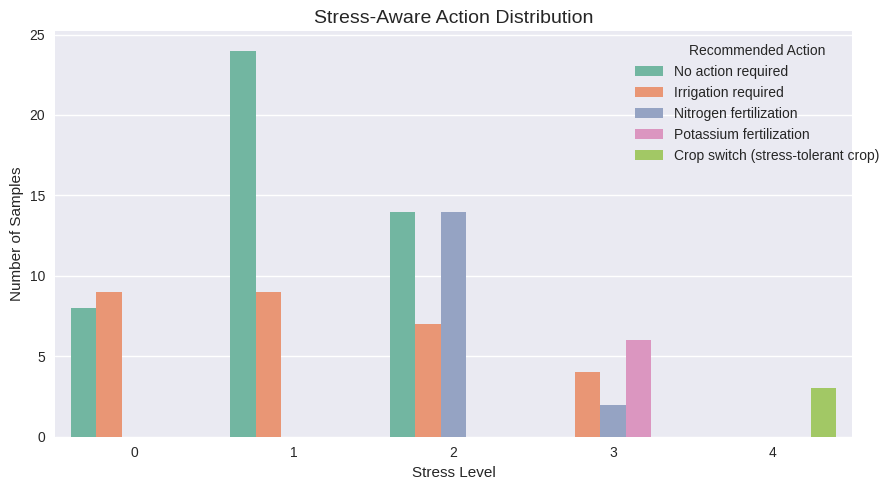

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# Generate action outputs for first 100 samples
actions = []

for i in range(100):
    row = soil_df.iloc[i]
    action = recommend_action_from_data(row)
    actions.append(action)

viz_df = soil_df.iloc[:100].copy()
viz_df["Action"] = actions

plt.figure(figsize=(9,5))
sns.countplot(
    x="Stress_Level",
    hue="Action",
    data=viz_df,
    palette="Set2"
)
plt.title("Stress-Aware Action Distribution", fontsize=14)
plt.xlabel("Stress Level")
plt.ylabel("Number of Samples")
plt.legend(title="Recommended Action", bbox_to_anchor=(1.05,1))
plt.tight_layout()
plt.show()


/tmp/ipython-input-3062607003.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = viz_df.pivot_table(
/tmp/ipython-input-3062607003.py:10: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  numeric_pivot = pivot.applymap(lambda x: list(ACTION_MAP.values()).index(x) if pd.notna(x) else -1)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


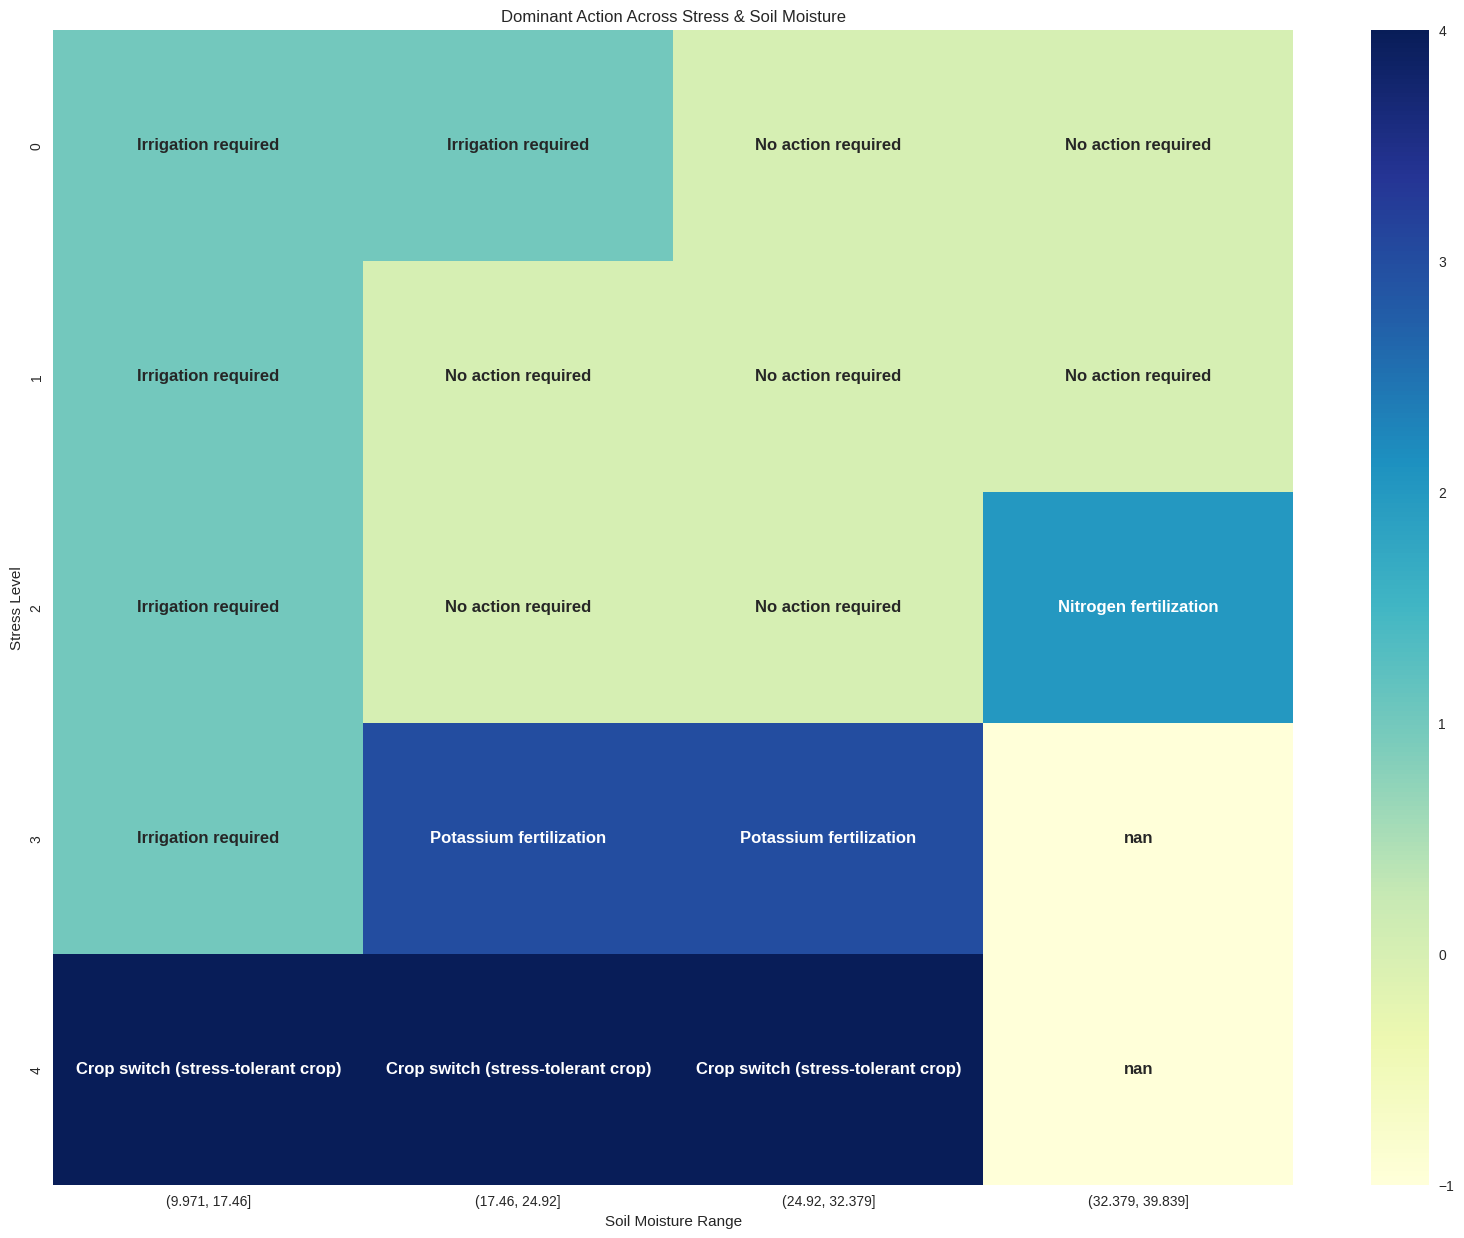

In [ ]:
pivot = viz_df.pivot_table(
    index="Stress_Level",
    columns=pd.cut(viz_df["Soil_Moisture"], bins=4),
    values="Action",
    aggfunc=lambda x: x.mode()[0]
)

plt.figure(figsize=(20,15))
# Create a numerical representation for the heatmap, handling NaN values
numeric_pivot = pivot.applymap(lambda x: list(ACTION_MAP.values()).index(x) if pd.notna(x) else -1)

sns.heatmap(
    numeric_pivot, # Use the numerical pivot for coloring
    annot=pivot,   # Keep the original pivot for annotations
    fmt="",
    cmap="YlGnBu",
    annot_kws={"size": 12, "weight": "bold"}
)
plt.title("Dominant Action Across Stress & Soil Moisture")
plt.ylabel("Stress Level")
plt.xlabel("Soil Moisture Range")
plt.show()

In [ ]:
fig = px.scatter(
    viz_df,
    x="Soil_Moisture",
    y="Nitrogen_Level",
    color="Action",
    symbol="Stress_Level",
    size="Potassium_Level",
    hover_data=["Stress_Level"],
    title="Interactive Stress–Soil–Action Relationship"
)

fig.show()


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



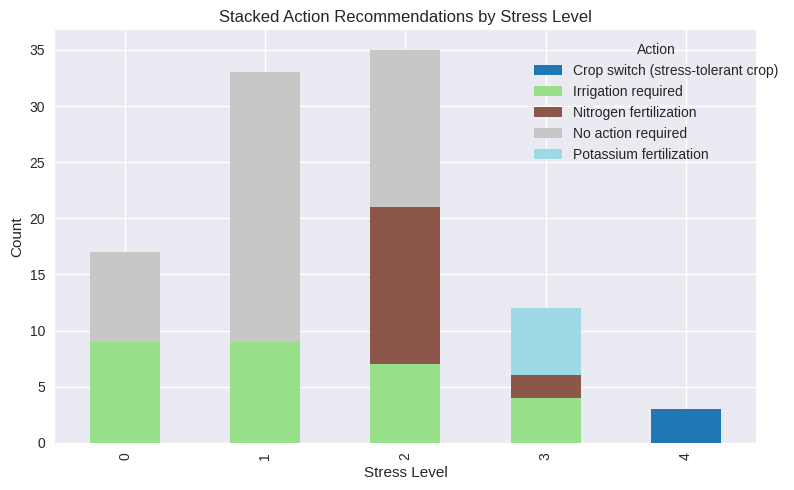

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



In [ ]:
action_counts = pd.crosstab(viz_df["Stress_Level"], viz_df["Action"])

action_counts.plot(
    kind="bar",
    stacked=True,
    colormap="tab20",
    figsize=(8,5)
)

plt.title("Stacked Action Recommendations by Stress Level")
plt.xlabel("Stress Level")
plt.ylabel("Count")
plt.legend(title="Action", bbox_to_anchor=(1.05,1))
plt.tight_layout()
plt.show()


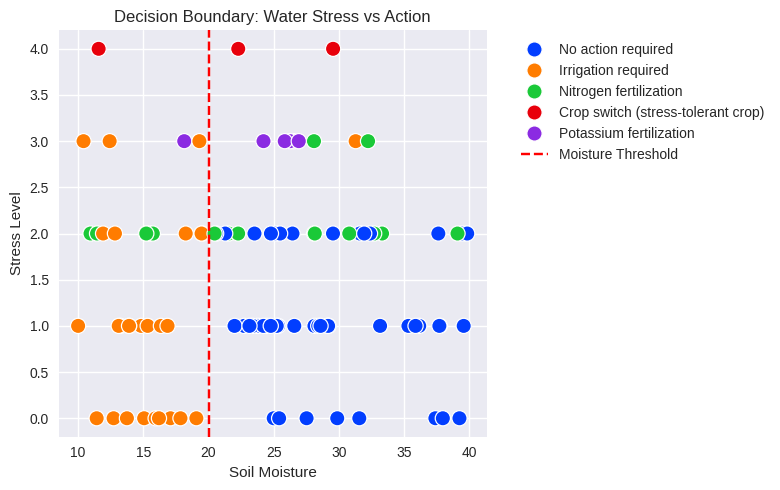

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



In [ ]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=viz_df,
    x="Soil_Moisture",
    y="Stress_Level",
    hue="Action",
    palette="bright",
    s=120
)

plt.axvline(20, color="red", linestyle="--", label="Moisture Threshold")
plt.title("Decision Boundary: Water Stress vs Action")
plt.xlabel("Soil Moisture")
plt.ylabel("Stress Level")
plt.legend(bbox_to_anchor=(1.05,1))
plt.tight_layout()
plt.show()


In [ ]:
import numpy as np

# =====================================================
# 2. ACTION SPACE (Copied from na4KlHW2NUb_)
# =====================================================
ACTION_MAP = {
    0: "No action required",
    1: "Irrigation required",
    2: "Nitrogen fertilization",
    3: "Potassium fertilization",
    4: "Crop switch (stress-tolerant crop)"
}

# =====================================================
# 3. DATA-DRIVEN DECISION FUNCTION (Copied from na4KlHW2NUb_)
# =====================================================
def recommend_action_from_data(row):
    stress = row["Stress_Level"]

    soil_moisture = row["Soil_Moisture"]
    nitrogen = row["Nitrogen_Level"]
    potassium = row["Potassium_Level"]

    # -------------------------------
    # Healthy / Low stress
    # -------------------------------
    if stress <= 1:
        if soil_moisture < 20:
            return ACTION_MAP[1]  # Irrigation
        else:
            return ACTION_MAP[0]  # No action

    # -------------------------------
    # Moderate stress
    # -------------------------------
    elif stress == 2:
        if nitrogen < 25:
            return ACTION_MAP[2]  # Nitrogen
        elif soil_moisture < 20:
            return ACTION_MAP[1]  # Irrigation
        else:
            return ACTION_MAP[0]

    # -------------------------------
    # High stress
    # -------------------------------
    elif stress == 3:
        if potassium < 30:
            return ACTION_MAP[3]  # Potassium
        elif nitrogen < 25:
            return ACTION_MAP[2]
        else:
            return ACTION_MAP[1]

    # -------------------------------
    # Extreme stress
    # -------------------------------
    elif stress == 4:
        return ACTION_MAP[4]  # Crop switch

# Add the 'Action' column to the df DataFrame
df["Action"] = df.apply(recommend_action_from_data, axis=1)

total = len(df)

# 1. Physiological consistency
def is_consistent(row):
    if row["Action"] == "Irrigation required" and row["Soil_Moisture"] < 20:
        return True
    if row["Action"] == "Nitrogen fertilization" and row["Nitrogen_Level"] < 25:
        return True
    if row["Action"] == "Potassium fertilization" and row["Potassium_Level"] < 30:
        return True
    if row["Action"] == "No action required" and row["Stress_Level"] <= 1:
        return True
    if row["Action"].startswith("Crop switch") and row["Stress_Level"] == 4:
        return True
    return False

consistency = df.apply(is_consistent, axis=1).mean() * 100

# 2. Dominant action purity
dominant_purity = (
    df.groupby("Stress_Level")["Action"]
    .apply(lambda x: x.value_counts(normalize=True).iloc[0])
    .mean() * 100
)

print(f"Physiological Consistency: {consistency:.1f}%")
print(f"Dominant Action Purity: {dominant_purity:.1f}%")

Physiological Consistency: 73.8%
Dominant Action Purity: 78.9%


In [ ]:
import pandas as pd

# Load your data
soil_df = pd.read_csv("/content/soil_with_crop_recommendations.csv")
vi_df   = pd.read_csv("/content/rl_vi_stress_output.csv")

min_len = min(len(soil_df), len(vi_df))
soil_df = soil_df.iloc[:min_len].reset_index(drop=True)
vi_df   = vi_df.iloc[:min_len].reset_index(drop=True)

# Merge stress
df = soil_df.copy()
df["Stress_Level"] = vi_df["Stress_Level"]


In [ ]:
def ndvi_action(row):
    if row["Stress_Level"] <= 1:
        return "No action required"
    elif row["Stress_Level"] == 2:
        return "Irrigation required"
    elif row["Stress_Level"] == 3:
        return "Nitrogen fertilization"
    else:
        return "Crop switch (stress-tolerant crop)"


In [ ]:
def mlvi_action(row):
    if row["Stress_Level"] <= 1:
        return "No action required"
    elif row["Stress_Level"] == 2:
        if row["Nitrogen_Level"] < 25:
            return "Nitrogen fertilization"
        else:
            return "Irrigation required"
    elif row["Stress_Level"] == 3:
        return "Potassium fertilization"
    else:
        return "Crop switch (stress-tolerant crop)"


In [ ]:
def rlvi_action(row):
    if row["Stress_Level"] <= 1:
        if row["Soil_Moisture"] < 20:
            return "Irrigation required"
        return "No action required"

    elif row["Stress_Level"] == 2:
        if row["Nitrogen_Level"] < 25:
            return "Nitrogen fertilization"
        return "Irrigation required"

    elif row["Stress_Level"] == 3:
        if row["Potassium_Level"] < 30:
            return "Potassium fertilization"
        return "Nitrogen fertilization"

    else:
        return "Crop switch (stress-tolerant crop)"


In [ ]:
df["Action_NDVI"] = df.apply(ndvi_action, axis=1)
df["Action_MLVI"] = df.apply(mlvi_action, axis=1)
df["Action_RLVI"] = df.apply(rlvi_action, axis=1)

df.head()


,Timestamp,Plant_ID,Soil_Moisture,Ambient_Temperature,Soil_Temperature,Humidity,Light_Intensity,Soil_pH,Nitrogen_Level,Phosphorus_Level,...,rainfall,label,Soil_Type,Crop1,Crop2,Crop3,Stress_Level,Action_NDVI,Action_MLVI,Action_RLVI
0,54:53.4,1.0,27.521109,22.240245,21.900435,55.291904,556.172805,5.581955,10.003650,45.806852,...,NaN,NaN,Slightly Acidic,Rice,Maize,Groundnut,0,No action required,No action required,No action required
1,54:53.4,1.0,14.835566,21.706763,18.680892,63.949181,596.136721,7.135705,30.712562,25.394393,...,NaN,NaN,Neutral,Wheat,Barley,Sugarcane,1,No action required,No action required,Irrigation required
2,54:53.4,1.0,17.086362,21.180946,15.392939,67.837956,591.124627,5.656852,29.337002,27.573892,...,NaN,NaN,Slightly Acidic,Rice,Maize,Groundnut,0,No action required,No action required,Irrigation required
3,54:53.4,1.0,15.336156,22.593302,22.778394,58.190811,241.412476,5.584523,16.966621,26.180705,...,NaN,NaN,Slightly Acidic,Rice,Maize,Groundnut,1,No action required,No action required,Irrigation required
4,54:53.4,1.0,39.822216,28.929001,18.100937,63.772036,444.493830,5.919707,10.944961,37.898907,...,NaN,NaN,Slightly Acidic,Rice,Maize,Groundnut,2,Irrigation required,Nitrogen fertilization,Nitrogen fertilization


In [ ]:
def compute_sari(df, stress_col, action_col):
    df_sorted = df.sort_values(stress_col).reset_index(drop=True)

    stress_changes = 0
    action_changes = 0

    for i in range(1, len(df_sorted)):
        if df_sorted.loc[i, stress_col] != df_sorted.loc[i-1, stress_col]:
            stress_changes += 1
            if df_sorted.loc[i, action_col] != df_sorted.loc[i-1, action_col]:
                action_changes += 1

    if stress_changes == 0:
        return 0.0

    return action_changes / stress_changes


In [ ]:
sari_ndvi = compute_sari(df, "Stress_Level", "Action_NDVI")
sari_mlvi = compute_sari(df, "Stress_Level", "Action_MLVI")
sari_rlvi = compute_sari(df, "Stress_Level", "Action_RLVI")

print("SARI (NDVI):", round(sari_ndvi, 2))
print("SARI (MLVI):", round(sari_mlvi, 2))
print("SARI (RL-VI):", round(sari_rlvi, 2))


SARI (NDVI): 0.75
SARI (MLVI): 0.75
SARI (RL-VI): 0.5


In [ ]:
def soil_changed(row1, row2):
    return (
        abs(row1["Soil_Moisture"] - row2["Soil_Moisture"]) > 5 or
        abs(row1["Nitrogen_Level"] - row2["Nitrogen_Level"]) > 5 or
        abs(row1["Potassium_Level"] - row2["Potassium_Level"]) > 5
    )


In [ ]:
def compute_csari(df, stress_col, action_col):
    df_sorted = df.sort_values(stress_col).reset_index(drop=True)

    valid_transitions = 0
    justified_action_changes = 0

    for i in range(1, len(df_sorted)):
        stress_diff = df_sorted.loc[i, stress_col] != df_sorted.loc[i-1, stress_col]

        if stress_diff and soil_changed(df_sorted.loc[i], df_sorted.loc[i-1]):
            valid_transitions += 1

            if df_sorted.loc[i, action_col] != df_sorted.loc[i-1, action_col]:
                justified_action_changes += 1

    if valid_transitions == 0:
        return 0.0

    return justified_action_changes / valid_transitions


In [ ]:
csari_ndvi = compute_csari(df, "Stress_Level", "Action_NDVI")
csari_mlvi = compute_csari(df, "Stress_Level", "Action_MLVI")
csari_rlvi = compute_csari(df, "Stress_Level", "Action_RLVI")

print("CSARI (NDVI):", round(csari_ndvi, 2))
print("CSARI (MLVI):", round(csari_mlvi, 2))
print("CSARI (RL-VI):", round(csari_rlvi, 2))


CSARI (NDVI): 0.75
CSARI (MLVI): 0.75
CSARI (RL-VI): 0.5


In [ ]:
def ndvi_stress(ndvi):
    if ndvi > 0.6:
        return 0
    elif ndvi > 0.45:
        return 1
    elif ndvi > 0.3:
        return 2
    elif ndvi > 0.2:
        return 3
    else:
        return 4


In [ ]:
df["NDVI"] = vi_df["RL_VI"]
df["Stress_NDVI"] = df["NDVI"].apply(ndvi_stress)

In [ ]:
def mlvi_stress(mlvi):
    return int(np.clip(round(mlvi * 4), 0, 4))


In [ ]:
df["MLVI"] = vi_df["RL_VI"]
df["Stress_MLVI"] = df["MLVI"].apply(mlvi_stress)

In [ ]:
df["Stress_RLVI"] = df["Stress_Level"]  # existing


In [ ]:
df["Action_NDVI"] = df.apply(lambda r: ndvi_action({**r.to_dict(), "Stress_Level": r["Stress_NDVI"]}), axis=1)
df["Action_MLVI"] = df.apply(lambda r: mlvi_action({**r.to_dict(), "Stress_Level": r["Stress_MLVI"]}), axis=1)
df["Action_RLVI"] = df.apply(lambda r: rlvi_action({**r.to_dict(), "Stress_Level": r["Stress_RLVI"]}), axis=1)

In [ ]:
csari_ndvi = compute_csari(df, "Stress_NDVI", "Action_NDVI")
csari_mlvi = compute_csari(df, "Stress_MLVI", "Action_MLVI")
csari_rlvi = compute_csari(df, "Stress_RLVI", "Action_RLVI")

print("CSARI (NDVI):", round(csari_ndvi, 2))
print("CSARI (MLVI):", round(csari_mlvi, 2))
print("CSARI (RL-VI):", round(csari_rlvi, 2))


CSARI (NDVI): 0.75
CSARI (MLVI): 0.75
CSARI (RL-VI): 0.5


In [ ]:
import pandas as pd

# Ensure categorical order
stress_order = [0, 1, 2, 3, 4]
action_order = [
    "No action required",
    "Irrigation required",
    "Nitrogen fertilization",
    "Potassium fertilization",
    "Crop switch (stress-tolerant crop)"
]

# Create transition matrix (counts)
transition_matrix = pd.crosstab(
    df["Stress_Level"],
    df["Action_RLVI"]
).reindex(index=stress_order, columns=action_order)

transition_matrix


NameError: name 'df' is not defined

In [ ]:
import pandas as pd

# Load your data
soil_df = pd.read_csv("/content/soil_with_crop_recommendations.csv")
vi_df   = pd.read_csv("/content/rl_vi_stress_output.csv")

min_len = min(len(soil_df), len(vi_df))
soil_df = soil_df.iloc[:min_len].reset_index(drop=True)
vi_df   = vi_df.iloc[:min_len].reset_index(drop=True)

# Merge stress
df = soil_df.copy()
df["Stress_Level"] = vi_df["Stress_Level"]

In [ ]:
Stress_Level = 2
Action_RLVI  = "Nitrogen fertilization"


In [ ]:
import pandas as pd

# Ensure categorical order
stress_order = [0, 1, 2, 3, 4]
action_order = [
    "No action required",
    "Irrigation required",
    "Nitrogen fertilization",
    "Potassium fertilization",
    "Crop switch (stress-tolerant crop)"
]

# Create transition matrix (counts)
transition_matrix = pd.crosstab(
    df["Stress_Level"],
    df["Action_RLVI"]
).reindex(index=stress_order, columns=action_order)

transition_matrix


KeyError: 'Action_RLVI'

In [ ]:
def rlvi_action(row):
    if row["Stress_Level"] <= 1:
        if row["Soil_Moisture"] < 20:
            return "Irrigation required"
        return "No action required"

    elif row["Stress_Level"] == 2:
        if row["Nitrogen_Level"] < 25:
            return "Nitrogen fertilization"
        return "Irrigation required"

    elif row["Stress_Level"] == 3:
        if row["Potassium_Level"] < 30:
            return "Potassium fertilization"
        return "Nitrogen fertilization"

    else:
        return "Crop switch (stress-tolerant crop)"

In [ ]:
df["Action_NDVI"] = df.apply(lambda r: ndvi_action({**r.to_dict(), "Stress_Level": r["Stress_NDVI"]}), axis=1)
df["Action_MLVI"] = df.apply(lambda r: mlvi_action({**r.to_dict(), "Stress_Level": r["Stress_MLVI"]}), axis=1)
df["Action_RLVI"] = df.apply(lambda r: rlvi_action({**r.to_dict(), "Stress_Level": r["Stress_RLVI"]}), axis=1)

NameError: name 'ndvi_action' is not defined

In [ ]:
print(df.columns)

Index(['Timestamp', 'Plant_ID', 'Soil_Moisture', 'Ambient_Temperature',
       'Soil_Temperature', 'Humidity', 'Light_Intensity', 'Soil_pH',
       'Nitrogen_Level', 'Phosphorus_Level', 'Potassium_Level',
       'Chlorophyll_Content', 'Electrochemical_Signal', 'Plant_Health_Status',
       'rainfall', 'label', 'Soil_Type', 'Crop1', 'Crop2', 'Crop3',
       'Stress_Level'],
      dtype='object')


In [ ]:
transition_prob = transition_matrix.div(
    transition_matrix.sum(axis=1), axis=0
)

transition_prob


NameError: name 'transition_matrix' is not defined

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 3.5))  # IEEE single-column friendly

sns.heatmap(
    transition_prob,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    cbar_kws={"label": "Action Probability"}
)

plt.xlabel("Recommended Action")
plt.ylabel("Stress Level")
plt.title("Stress vs Action Transition Matrix")

plt.tight_layout()
plt.show()


NameError: name 'transition_prob' is not defined

<Figure size 500x350 with 0 Axes>

In [ ]:
def ndvi_action(row, stress_col):
    stress = row[stress_col]

    if stress <= 1:
        return "No action required"
    elif stress == 2:
        return "Irrigation required"
    elif stress == 3:
        return "Nitrogen fertilization"
    else:
        return "Crop switch (stress-tolerant crop)"


In [ ]:
def mlvi_action(row, stress_col):
    stress = row[stress_col]

    if stress <= 1:
        return "No action required"

    elif stress == 2:
        if row["Nitrogen_Level"] < 25:
            return "Nitrogen fertilization"
        else:
            return "Irrigation required"

    elif stress == 3:
        return "Potassium fertilization"

    else:
        return "Crop switch (stress-tolerant crop)"


In [ ]:
def rlvi_action(row, stress_col):
    stress = row[stress_col]

    if stress <= 1:
        if row["Soil_Moisture"] < 20:
            return "Irrigation required"
        return "No action required"

    elif stress == 2:
        if row["Nitrogen_Level"] < 25:
            return "Nitrogen fertilization"
        return "Irrigation required"

    elif stress == 3:
        if row["Potassium_Level"] < 30:
            return "Potassium fertilization"
        return "Nitrogen fertilization"

    else:
        return "Crop switch (stress-tolerant crop)"


In [ ]:
df["Action_NDVI"] = df.apply(lambda r: ndvi_action(r, "Stress_NDVI"), axis=1)
df["Action_MLVI"] = df.apply(lambda r: mlvi_action(r, "Stress_MLVI"), axis=1)
df["Action_RLVI"] = df.apply(lambda r: rlvi_action(r, "Stress_RLVI"), axis=1)


KeyError: 'Stress_NDVI'

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("/content/agriculture_dataset (1).csv")

print(df.head())
print(df.columns)
print(df.info())


   High_Resolution_RGB  Multispectral_Images  Thermal_Images  Temporal_Images  \
0                    0                     0               0                0   
1                    1                     1               0                0   
2                    0                     0               0                0   
3                    0                     0               0                0   
4                    0                     1               1                1   

   Spatial_Resolution  GPS_Coordinates  Field_Boundaries  Elevation_Data  \
0            0.667324           201538                 3       28.207634   
1            1.459000           215854                 3       82.335147   
2            0.500442           890802                 3       83.865629   
3            1.865161           605584                 3       20.747905   
4            1.392331           871732                 3       22.588815   

   Canopy_Coverage      NDVI  ...  Weed_Coverage  Pest_D

In [ ]:
stress_map = {
    "Healthy": 0,
    "Low": 1,
    "Moderate": 2,
    "High": 3,
    "Severe": 4
}

# If already numeric, skip mapping
if df["Crop_Health_Label"].dtype == object:
    df["stress_t"] = df["Crop_Health_Label"].map(stress_map)
else:
    df["stress_t"] = df["Crop_Health_Label"]

df["stress_t"] = df["stress_t"].astype(int)

In [ ]:
from sklearn.preprocessing import MinMaxScaler

env_features = [
    "Temperature", "Humidity", "Rainfall",
    "Soil_Moisture",
    "Soil_pH"
]

scaler = MinMaxScaler()
df[env_features] = scaler.fit_transform(df[env_features])


In [ ]:
def forecast_stress(row):
    s = row["stress_t"]

    # Water stress
    if row["Soil_Moisture"] < 0.35:
        s += 1

    # Climate stress
    if row["Temperature"] > 0.7 or row["Rainfall"] < 0.3:
        s += 1

    return min(s, 4)

df["stress_forecast"] = df.apply(forecast_stress, axis=1)


In [ ]:
def recommend_action(row):

    if row["stress_forecast"] <= 1:
        return "No Action"

    if row["Soil_Moisture"] < 0.35:
        return "Irrigation"

    # Removed conditions for Nitrogen and Potassium as these columns are not present in the current df

    return "Crop Switch"

df["recommended_action"] = df.apply(recommend_action, axis=1)


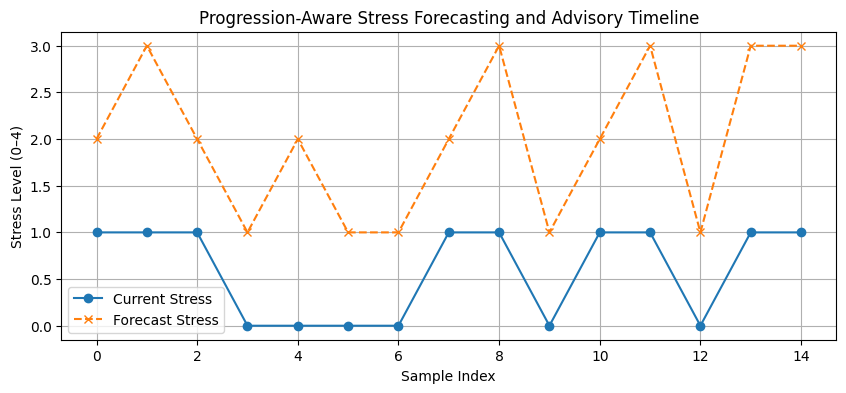

In [ ]:
plt.figure(figsize=(10,4))
plt.plot(df["stress_t"][:15], marker="o", label="Current Stress")
plt.plot(df["stress_forecast"][:15], marker="x", linestyle="--",
         label="Forecast Stress")

plt.xlabel("Sample Index")
plt.ylabel("Stress Level (0–4)")
plt.title("Progression-Aware Stress Forecasting and Advisory Timeline")
plt.legend()
plt.grid(True)
plt.show()


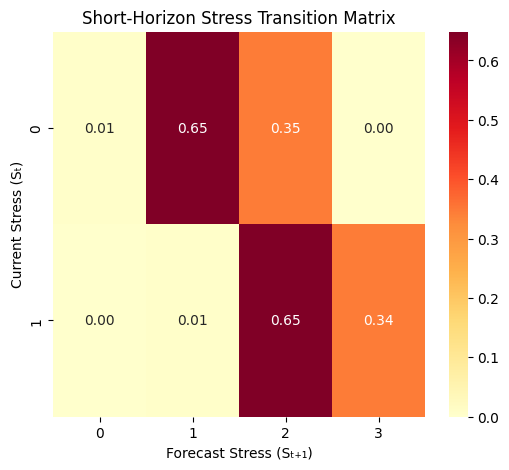

In [ ]:
transition = pd.crosstab(
    df["stress_t"], df["stress_forecast"],
    normalize="index"
)

plt.figure(figsize=(6,5))
sns.heatmap(transition, annot=True, cmap="YlOrRd", fmt=".2f")
plt.xlabel("Forecast Stress (Sₜ₊₁)")
plt.ylabel("Current Stress (Sₜ)")
plt.title("Short-Horizon Stress Transition Matrix")
plt.show()


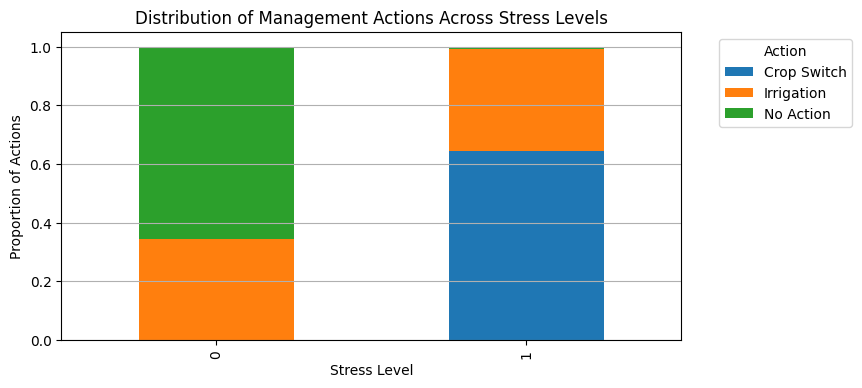

In [ ]:
action_dist = (
    df.groupby("stress_t")["recommended_action"]
      .value_counts(normalize=True)
      .unstack()
      .fillna(0)
)

action_dist.plot(kind="bar", stacked=True, figsize=(8,4))
plt.ylabel("Proportion of Actions")
plt.xlabel("Stress Level")
plt.title("Distribution of Management Actions Across Stress Levels")
plt.legend(title="Action", bbox_to_anchor=(1.05,1))
plt.grid(axis="y")
plt.show()


In [ ]:
df["moisture_bin"] = pd.cut(
    df["Soil_Moisture"],
    bins=[0, 0.35, 0.65, 1.0],
    labels=["Low", "Medium", "High"]
)

heatmap_data = pd.crosstab(
    df["stress_t"],
    df["moisture_bin"],
    values=df["recommended_action"],
    aggfunc=lambda x: x.mode()[0] if len(x) else None
)

print(heatmap_data)


moisture_bin         Low       Medium         High
stress_t                                          
0             Irrigation    No Action    No Action
1             Irrigation  Crop Switch  Crop Switch


In [ ]:
advisory_table = df[
    ["stress_t", "stress_forecast",
     "Soil_Moisture",
     "recommended_action"]
]

print(advisory_table.head(10))


   stress_t  stress_forecast  Soil_Moisture recommended_action
0         1                2       0.867021        Crop Switch
1         1                3       0.247631         Irrigation
2         1                2       0.781825        Crop Switch
3         0                1       0.781701          No Action
4         0                2       0.109830         Irrigation
5         0                1       0.959816          No Action
6         0                1       0.745796          No Action
7         1                2       0.555407        Crop Switch
8         1                3       0.068416         Irrigation
9         0                1       0.852590          No Action


In [ ]:
!pip install shap


In [ ]:
# Features used for forecasting
feature_cols = [
    "Temperature", "Humidity", "Rainfall",
    "Soil_Moisture",
    "Soil_pH"
]

X = df[feature_cols]
y = df["stress_forecast"]


In [ ]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=200,
    max_depth=6,
    random_state=42
)

model.fit(X, y)


RandomForestClassifier(max_depth=6, n_estimators=200, random_state=42)

In [ ]:
import shap

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X)

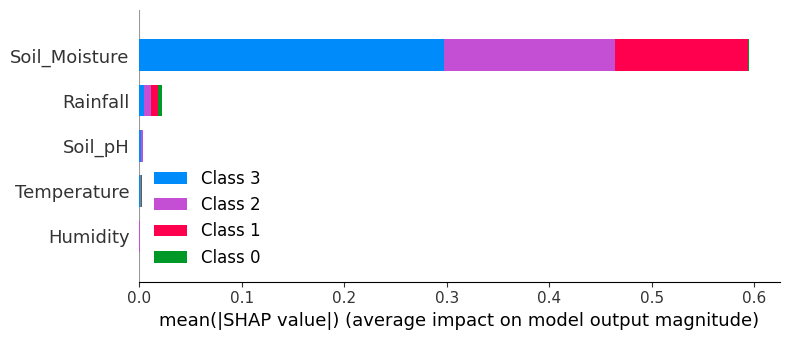

In [ ]:
shap.summary_plot(
    shap_values,
    X,
    plot_type="bar",
    show=True
)


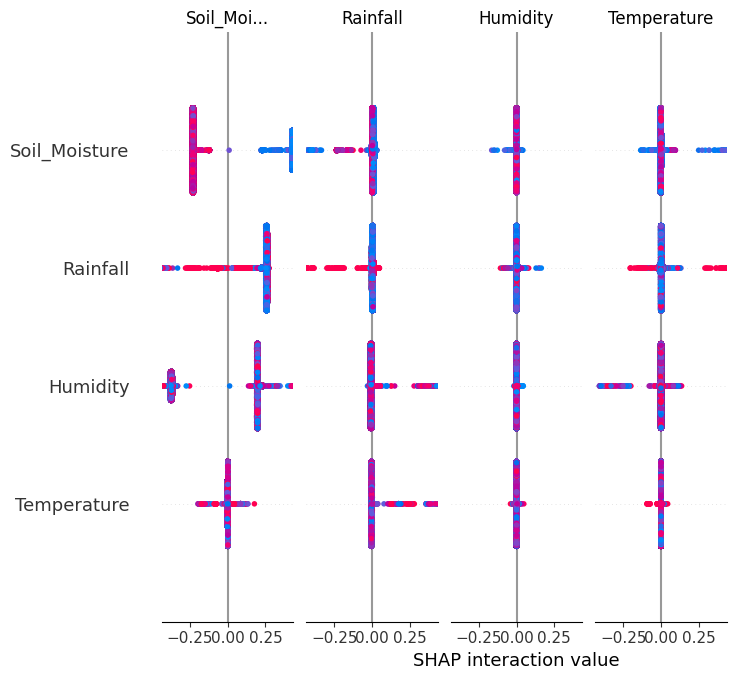

In [ ]:
shap.summary_plot(
    shap_values,
    X,
    show=True
)


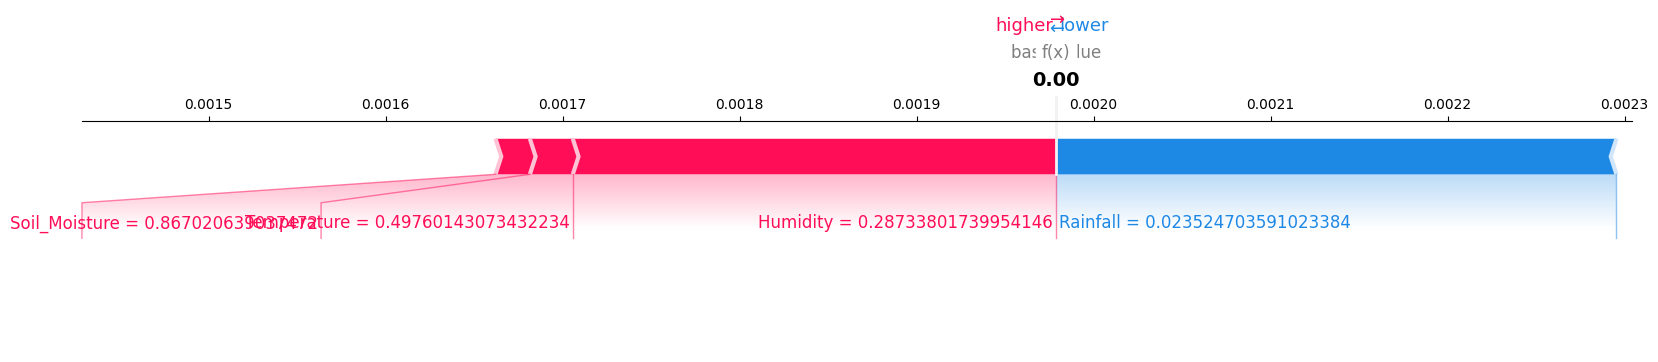

In [ ]:
sample_id = 0
shap.force_plot(
    explainer.expected_value[0],
    shap_values[0][sample_id],
    X.iloc[sample_id].values[:4], # Provide only the first 4 feature values
    feature_names=X.columns[:4],  # Provide only the first 4 feature names
    matplotlib=True
)

In [ ]:
y_binary = (df["stress_forecast"] >= 2).astype(int)


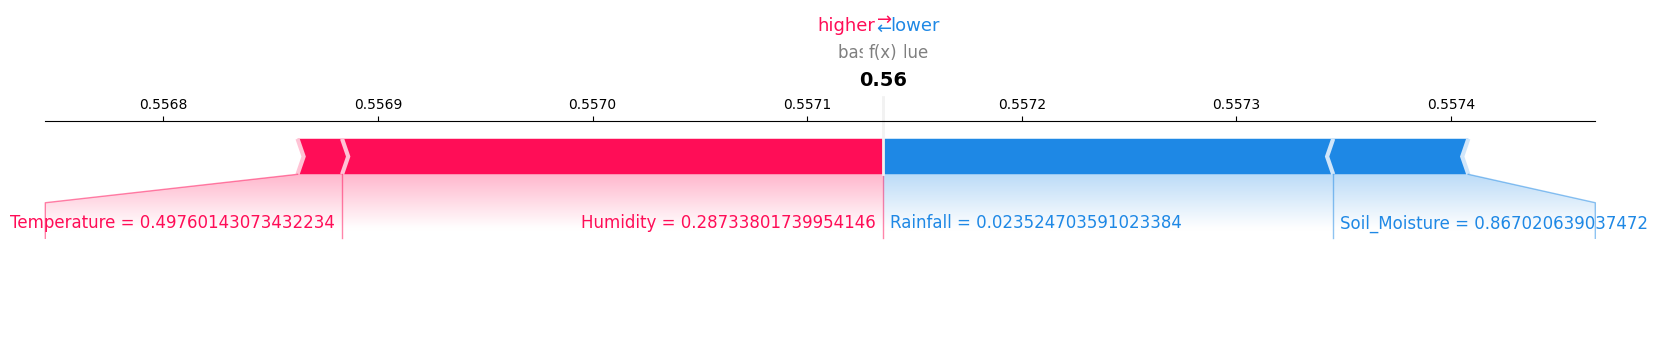

In [ ]:
i = 0
pred_class = model.predict(X.iloc[[i]])[0]

shap.force_plot(
    explainer.expected_value[pred_class],
    shap_values[pred_class][i],
    X.iloc[i].values[:4], # Slice to match the 4 SHAP values
    feature_names=X.columns[:4], # Slice to match the 4 SHAP values
    matplotlib=True
)